# ЛР2. Пункт 0: проверка оракулов и методов

Ноутбук лежит в папке `lab2/` рядом с `oracles/`, `methods/`, `scripts/`.
Дописаны все `# TODO`:

| Файл | Что дописано |
|---|---|
| `oracles/quadratic.py` | `x* = A⁻¹b`, `grad = Ax − b`, `hess = A`; опция `spectrum` (linspace / uniform / loguniform) |
| `oracles/logistic.py` | функция потерь через `logaddexp`, градиент, гессиан `Xᵀ diag(σ(1−σ)) X / n + l2·I`, свойство `info` с L и μ |
| `methods/gd.py` | шаг `x − η·∇f` |
| `methods/adaptive_step.py` | шаги Поляка, Барзилаи–Борвейна (BB1, BB2), бэктрекинг Армихо |

## 1. Проверки из README

In [1]:
!python -m scripts.run_experiment --config configs/quadratic_gd.yaml
!python -m scripts.run_experiment --config configs/logistic_gd.yaml
!python -m scripts.run_experiment --config configs/quadratic_adaptive.yaml

[checks] oracle = quadratic(dim=50, kappa=100)
[checks] grad vs finite-diff: max err = 1.59e-09
[checks] hess PSD: min eig = 1.00e-02
[checks] GD decreases loss: OK


[checks] GD converges: OK


Saved: results/logs/quadratic__gd__seed42.json


[checks] oracle = logistic(n=500, dim=20, l2=1)
[checks] grad vs finite-diff: max err = 1.27e-09
[checks] hess PSD: min eig = 1.01e+00


[checks] GD decreases loss: OK
[checks] GD converges: OK
Saved: results/logs/logistic__gd__seed42.json


[checks] oracle = quadratic(dim=50, kappa=1000)
[checks] grad vs finite-diff: max err = 1.90e-09
[checks] hess PSD: min eig = 1.00e-03
[checks] GD decreases loss: OK


[checks] GD converges: OK
Saved: results/logs/quadratic__adaptive__seed42.json


Все проверки должны вывести `OK`. Замечание: основной запуск `quadratic_gd.yaml` использует шаг 0.01 из конфига,
а не 1/L = 1, поэтому за 5000 итераций не доходит до `tol`. Это иллюстрация слишком маленького шага, а не ошибка.

## 2. Дополнительные проверки: гессиан логистики и адаптивные методы

logistic: max |hess - FD| = 1.5e-10



метод           итераций     f - f*
GD, шаг 1/L         9997    5.0e-08
backtrack           9997    5.0e-08
polyak               739    1.4e-08
bb1                  278    3.7e-08
bb2                  263    4.3e-09


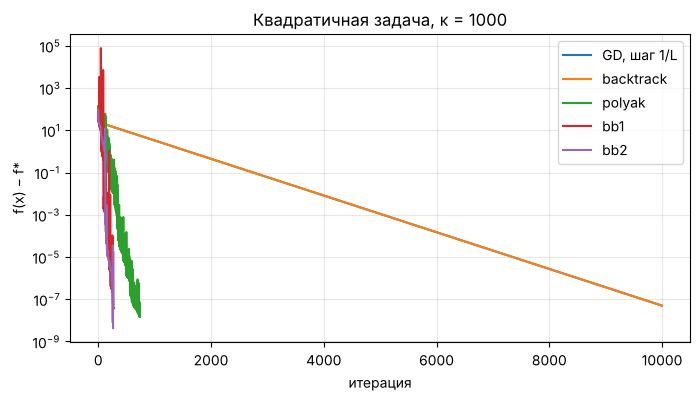

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from oracles import QuadraticOracle, LogisticOracle
from methods import GD, AdaptiveStep

# гессиан логистики против конечных разностей градиента
o = LogisticOracle(n=500, dim=20, l2=1.0)
x = np.random.default_rng(1).standard_normal(20)
h = 1e-6
H_fd = np.column_stack([(o.grad(x + h*e) - o.grad(x - h*e)) / (2*h) for e in np.eye(20)])
print(f"logistic: max |hess - FD| = {np.abs(o.hess(x) - H_fd).max():.1e}")

# сравнение методов на плохо обусловленной квадратичной задаче
q = QuadraticOracle(dim=50, kappa=1000)
x0 = np.zeros(50)
runs = {"GD, шаг 1/L": GD(q, max_iter=20000, tol=1e-5).run(x0)}
for s in ["backtrack", "polyak", "bb1", "bb2"]:
    runs[s] = AdaptiveStep(q, strategy=s, eta0=1.0, max_iter=20000, tol=1e-5).run(x0)

print(f"\n{'метод':14s} {'итераций':>9s} {'f - f*':>10s}")
for name, hist in runs.items():
    print(f"{name:14s} {len(hist.f)-1:9d} {hist.f[-1] - q.info.f_star:10.1e}")

fig, ax = plt.subplots(figsize=(8, 4))
for name, hist in runs.items():
    ax.semilogy(np.maximum(np.array(hist.f) - q.info.f_star, 1e-16), label=name)
ax.set_xlabel("итерация"); ax.set_ylabel("f(x) − f*")
ax.set_title("Квадратичная задача, κ = 1000"); ax.grid(True, which="both", alpha=.3); ax.legend()
plt.show()